# Aluminium crack-tip inverse elasticity

This active review fits **all 44,581 measured points** through the selected six-order Williams displacement expansion. It infers stress and opening/sliding intensity; stress is not directly observed. The archived original method is a **baseline**, not physical truth. The task implements the displacement-only direct fitting case described in the plans. Other upstream integral/CJP analyses require additional measurements and are not silently represented as computed comparisons here.

The six review stages are observations, physics/reference roles, fresh inference, quantitative comparison/residuals, order ablation, and robustness/conclusion.

In [1]:
from pathlib import Path
import sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.solvers import reconstruct
from src.physics_model import stress_field,TERMS
from src.main import run
coordinates,displacements=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in z.files}
print('Measured point count:',len(coordinates),'Original keys:',list(upstream))


Measured point count: 44581 Original keys: ['reconstruction', 'stress_intensity', 'runtime_seconds']


## 1. Measured optical displacements

The two arrays are point positions and displacement vectors in mm, in the laboratory frame. The calibrated tip and angle rotate both arrays consistently. No strain or stress target is supplied to reconstruction.

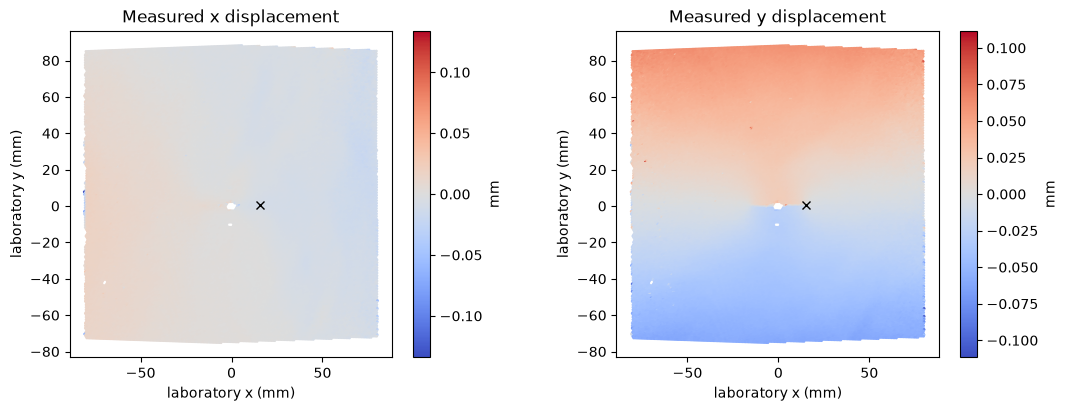

In [2]:
fig,ax=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for i,a in enumerate(ax):
    im=a.scatter(coordinates[:,0],coordinates[:,1],c=displacements[:,i],s=1,cmap='coolwarm',vmin=-np.max(np.abs(displacements[:,i])),vmax=np.max(np.abs(displacements[:,i])))
    a.plot(15.39,.40,'kx',label='calibrated tip');a.set(xlabel='laboratory x (mm)',ylabel='laboratory y (mm)',title=['Measured x displacement','Measured y displacement'][i]);a.set_aspect('equal');fig.colorbar(im,ax=a,label='mm')
plt.show()


## 2. Physics and reference roles

For $G=E/[2(1+\nu)]$ and $\kappa=(3-\nu)/(1+\nu)$, the local eigenfield basis evaluates the radial/trigonometric displacement formulas in the README. The coefficient vector includes symmetric and antisymmetric orders $n=-1,1,2,3,4,5$. The inverse minimizes $\|Ac-d\|_2^2/2$, where $d$ stacks interpolated, tip-rebased x/y displacements. Analytical derivatives give plane-stress components. Singular coefficients map to $[K_I,K_{II}]=\sqrt{2\pi/1000}[a(1),-b(1)]$ in MPa sqrt(m).

The hidden baseline and upstream measurements are independently captured original calculations on these observations. Their agreement with a fresh run validates extraction; it does not measure model bias, DIC calibration uncertainty or actual stress accuracy.

## 3. Fresh full reconstruction

The next cell actively runs the full standard local method and writes both declared output quantities. No cached array is substituted.

Fresh runtime (s): 0.4487702999613248 rank: 12 equations: 258258
Fresh KI/KII (MPa sqrt(m)): [7.17920582 3.47752864]
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0000000000000002,
    "reconstruction_nrmse": 9.551964330154104e-16,
    "stress_intensity_ncc": 1.0,
    "stress_intensity_nrmse": 6.120596838322759e-15
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "stress_intensity_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "stress_intensity_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


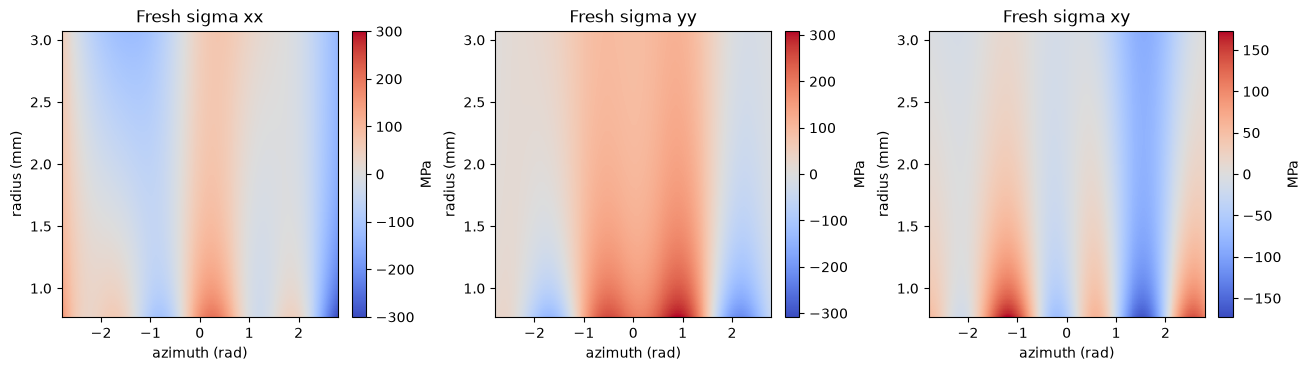

In [3]:
stress,intensity,info,runtime=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
print('Fresh runtime (s):',runtime,'rank:',info['rank'],'equations:',len(info['b']))
print('Fresh KI/KII (MPa sqrt(m)):',intensity)
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert result.returncode==0,result.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text());print(json.dumps(report,indent=2))
fig,axs=plt.subplots(1,3,figsize=(13,3.6),constrained_layout=True)
for k,ax in enumerate(axs):
    im=ax.pcolormesh(info['phi'][0],info['r'][:,0],stress[k],shading='auto',cmap='coolwarm',vmin=-np.max(np.abs(stress[k])),vmax=np.max(np.abs(stress[k])));ax.set(xlabel='azimuth (rad)',ylabel='radius (mm)',title=['Fresh sigma xx','Fresh sigma yy','Fresh sigma xy'][k]);fig.colorbar(im,ax=ax,label='MPa')
plt.show()


## 4. Original comparison and observation residuals

Each component is compared on the same fixed annulus, without alignment or scaling. Displacement residuals expose the mismatch between measurements and this truncated linear-elastic model. A small extraction error does not force a small physical residual.

Maximum original/local stress difference (MPa): 1.5347723092418164e-12
Observation displacement RMSE (mm): 0.0008683199250469595


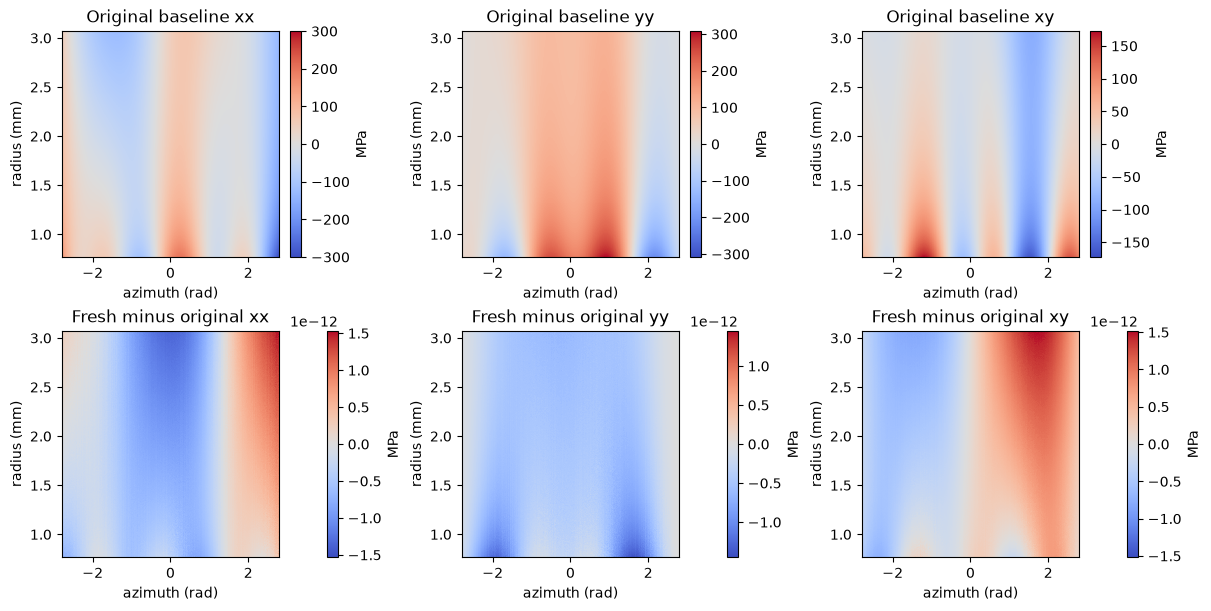

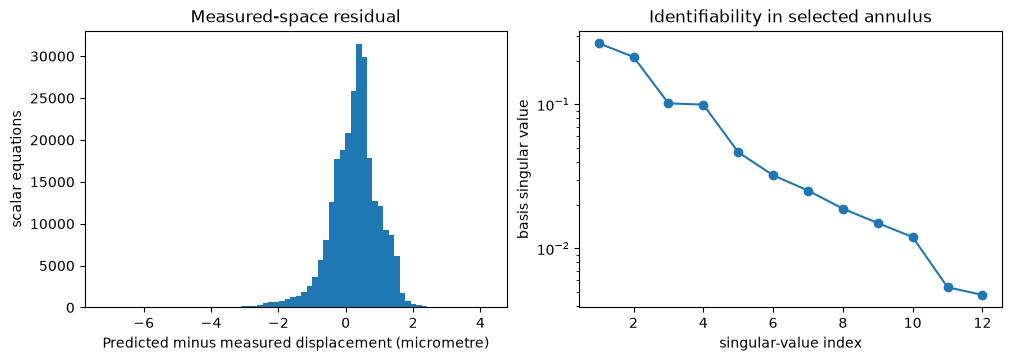

In [4]:
# Upstream fields are identified original measurements, not fresh or ground truth.
reference=upstream['reconstruction'][0] if 'reconstruction' in upstream else upstream['output_stress']
reference_k=upstream['stress_intensity'][0] if 'stress_intensity' in upstream else upstream['output_stress_intensity']
if reference.ndim==4:reference=reference[0]
print('Maximum original/local stress difference (MPa):',np.max(np.abs(stress-reference)))
print('Observation displacement RMSE (mm):',np.sqrt(np.mean(info['residual']**2)))
fig,axs=plt.subplots(2,3,figsize=(12,6),constrained_layout=True)
for k in range(3):
    for row,field,label in [(0,reference[k],'Original baseline'),(1,stress[k]-reference[k],'Fresh minus original')]:
        bound=max(np.max(np.abs(field)),np.finfo(float).tiny)
        im=axs[row,k].pcolormesh(info['phi'][0],info['r'][:,0],field,shading='auto',cmap='coolwarm',vmin=-bound,vmax=bound);axs[row,k].set(title=label+' '+['xx','yy','xy'][k],xlabel='azimuth (rad)',ylabel='radius (mm)');fig.colorbar(im,ax=axs[row,k],label='MPa')
plt.show()
fig,axs=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
axs[0].hist(info['residual']*1000,bins=70);axs[0].set(xlabel='Predicted minus measured displacement (micrometre)',ylabel='scalar equations',title='Measured-space residual')
axs[1].semilogy(np.arange(1,13),info['singular_values'],'o-');axs[1].set(xlabel='singular-value index',ylabel='basis singular value',title='Identifiability in selected annulus')
plt.show()


## 5. Truncation ablation

Compute a new fit retaining only order n=1. This is a deliberately changed model for diagnosis, not the shipped reconstruction. Compare both measured-space residual and inferred intensities; the effect of extra terms cannot be inferred from a cached full solution.

Full / singular-only displacement RMSE (mm): 0.0008683199250469595 0.00210350236722638


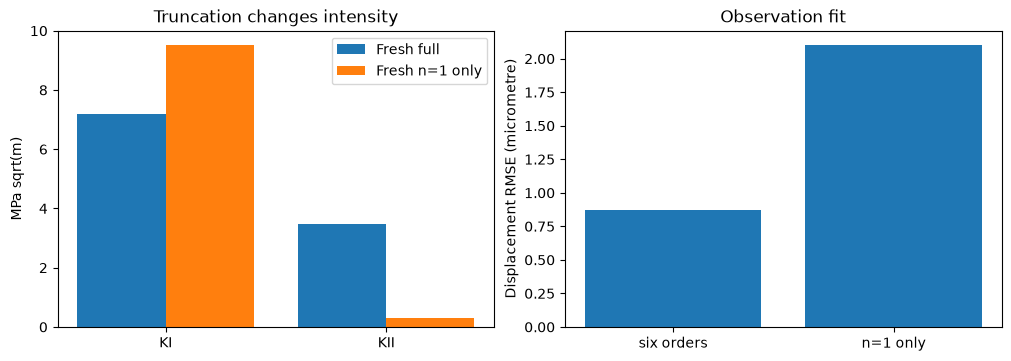

In [5]:
short_stress,short_k,short_info=reconstruct(coordinates,displacements,terms=np.array([1]))
full_rmse=float(np.sqrt(np.mean(info['residual']**2)));short_rmse=float(np.sqrt(np.mean(short_info['residual']**2)))
print('Full / singular-only displacement RMSE (mm):',full_rmse,short_rmse)
fig,ax=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
x=np.arange(2);ax[0].bar(x-.2,intensity,.4,label='Fresh full');ax[0].bar(x+.2,short_k,.4,label='Fresh n=1 only');ax[0].set(xticks=x,xticklabels=['KI','KII'],ylabel='MPa sqrt(m)',title='Truncation changes intensity');ax[0].legend()
ax[1].bar(['six orders','n=1 only'],[full_rmse*1000,short_rmse*1000]);ax[1].set(ylabel='Displacement RMSE (micrometre)',title='Observation fit')
plt.show()


## 6. Robustness and conclusion

Add reproducible independent Gaussian displacement perturbations of standard deviation 0.0001 mm to every measured component. This is a sensitivity experiment with a declared artificial noise scale, not a claim about instrument noise. Geometry, full sample count and output annulus remain fixed.

Stress relative L2 change: 0.032260489029335294 Intensity perturbation: [0.13092437 0.1689711 ]


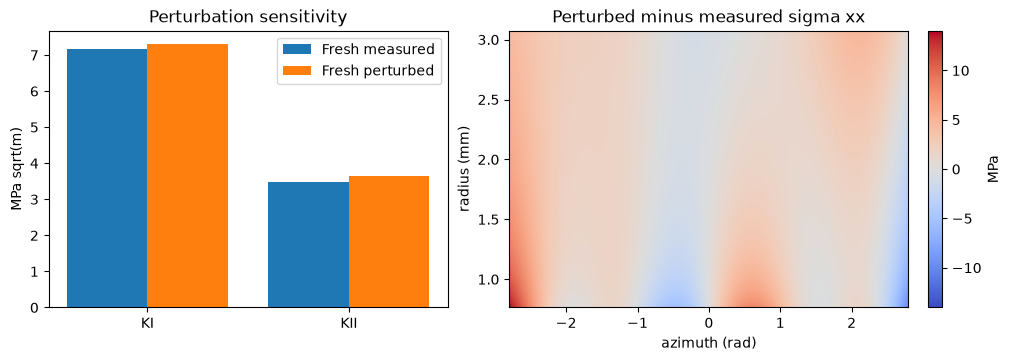

In [6]:
rng=np.random.default_rng(20261026)
noise_sigma=.0001
noisy_stress,noisy_k,noisy_info=reconstruct(coordinates,displacements+rng.normal(0,noise_sigma,displacements.shape))
relative=np.linalg.norm(noisy_stress-stress)/np.linalg.norm(stress)
print('Stress relative L2 change:',relative,'Intensity perturbation:',noisy_k-intensity)
fig,ax=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
ax[0].bar(x-.2,intensity,.4,label='Fresh measured');ax[0].bar(x+.2,noisy_k,.4,label='Fresh perturbed');ax[0].set(xticks=x,xticklabels=['KI','KII'],ylabel='MPa sqrt(m)',title='Perturbation sensitivity');ax[0].legend()
difference=noisy_stress[0]-stress[0];bound=np.max(np.abs(difference))
im=ax[1].pcolormesh(info['phi'][0],info['r'][:,0],difference,shading='auto',cmap='coolwarm',vmin=-bound,vmax=bound);ax[1].set(title='Perturbed minus measured sigma xx',xlabel='azimuth (rad)',ylabel='radius (mm)');fig.colorbar(im,ax=ax[1],label='MPa')
plt.show()


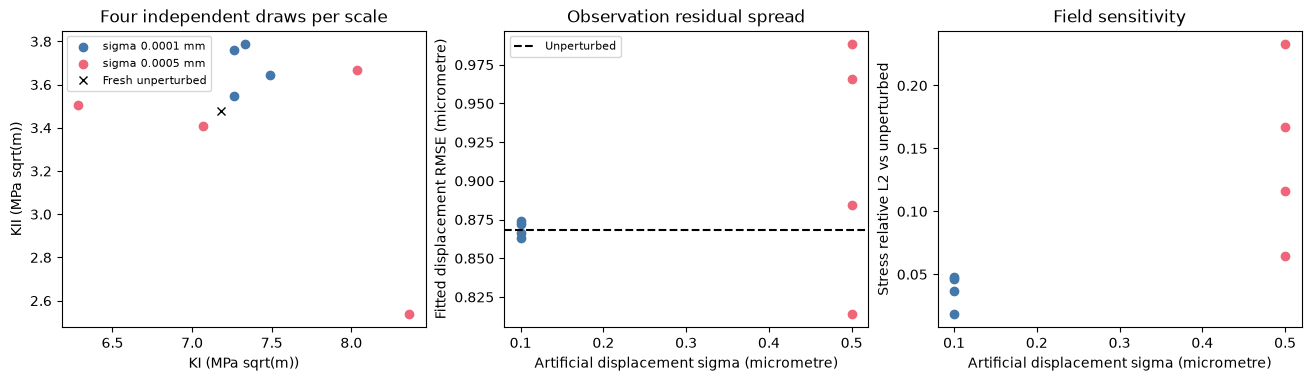

{
  "fresh_runtime_seconds": 0.4487702999613248,
  "fresh_intensity": [
    7.179205815846947,
    3.477528644646307
  ],
  "original_intensity": [
    7.179205815846979,
    3.4775286446463105
  ],
  "maximum_stress_parity_error_mpa": 1.5347723092418164e-12,
  "full_displacement_rmse_mm": 0.0008683199250469595,
  "singular_only_displacement_rmse_mm": 0.00210350236722638,
  "singular_only_intensity": [
    9.525903173572987,
    0.3009414126779167
  ],
  "noise_sigma_mm": 0.0001,
  "noise_stress_relative_l2": 0.032260489029335294,
  "noisy_intensity": [
    7.31013018495215,
    3.6464997448019627
  ],
  "noise_ensemble": [
    {
      "sigma_mm": 0.0001,
      "replicate": 0,
      "KI": 7.266018863655649,
      "KII": 3.547725573267938,
      "displacement_rmse_mm": 0.0008665193643096413,
      "stress_relative_l2_vs_unperturbed": 0.018469778445294377
    },
    {
      "sigma_mm": 0.0001,
      "replicate": 1,
      "KI": 7.49026989704171,
      "KII": 3.64373188927031,
      "displ

In [7]:
# Eight additional complete inversions; these are hypothetical perturbations.
ensemble_rng=np.random.default_rng(20261027)
noise_ensemble=[]
for sigma in [.0001,.0005]:
    for replicate in range(4):
        perturbed=displacements+sigma*ensemble_rng.normal(size=displacements.shape)
        es,ek,ei=reconstruct(coordinates,perturbed)
        noise_ensemble.append({'sigma_mm':sigma,'replicate':replicate,'KI':float(ek[0]),'KII':float(ek[1]),'displacement_rmse_mm':float(np.sqrt(np.mean(ei['residual']**2))),'stress_relative_l2_vs_unperturbed':float(np.linalg.norm(es-stress)/np.linalg.norm(stress))})
fig,ax=plt.subplots(1,3,figsize=(13,3.7),constrained_layout=True)
for sigma,color in zip([.0001,.0005],['#4477aa','#ee6677']):
    rows=[r for r in noise_ensemble if r['sigma_mm']==sigma]
    ax[0].scatter([r['KI'] for r in rows],[r['KII'] for r in rows],label=f'sigma {sigma:g} mm',color=color)
    ax[1].scatter([sigma*1000]*4,[r['displacement_rmse_mm']*1000 for r in rows],color=color)
    ax[2].scatter([sigma*1000]*4,[r['stress_relative_l2_vs_unperturbed'] for r in rows],color=color)
ax[0].plot(intensity[0],intensity[1],'kx',label='Fresh unperturbed');ax[0].set(xlabel='KI (MPa sqrt(m))',ylabel='KII (MPa sqrt(m))',title='Four independent draws per scale');ax[0].legend(fontsize=8)
ax[1].axhline(full_rmse*1000,color='black',linestyle='--',label='Unperturbed');ax[1].set(xlabel='Artificial displacement sigma (micrometre)',ylabel='Fitted displacement RMSE (micrometre)',title='Observation residual spread');ax[1].legend(fontsize=8)
ax[2].set(xlabel='Artificial displacement sigma (micrometre)',ylabel='Stress relative L2 vs unperturbed',title='Field sensitivity')
plt.show()
measurements={'fresh_runtime_seconds':runtime,'fresh_intensity':intensity.tolist(),'original_intensity':np.asarray(reference_k).reshape(-1).tolist(),'maximum_stress_parity_error_mpa':float(np.max(np.abs(stress-reference))),'full_displacement_rmse_mm':full_rmse,'singular_only_displacement_rmse_mm':short_rmse,'singular_only_intensity':short_k.tolist(),'noise_sigma_mm':noise_sigma,'noise_stress_relative_l2':float(relative),'noisy_intensity':noisy_k.tolist(),'noise_ensemble':noise_ensemble,'judge_metrics':report['metrics']}
print(json.dumps(measurements,indent=2))


The independent evaluator and stage tests establish numerical reproduction of the selected original direct fit. The residual, truncation and perturbation comparisons delimit what that fit supports. Elasticity, calibrated geometry, annulus choice and displacement quality remain modelling assumptions; no independent stress ground truth is available.